# **Self-RAG Step 1: Adaptive Retrieval Decision**

![Self-Reflective RAG Pipeline Infographic.png](<attachment:Self-Reflective RAG Pipeline Infographic.png>)

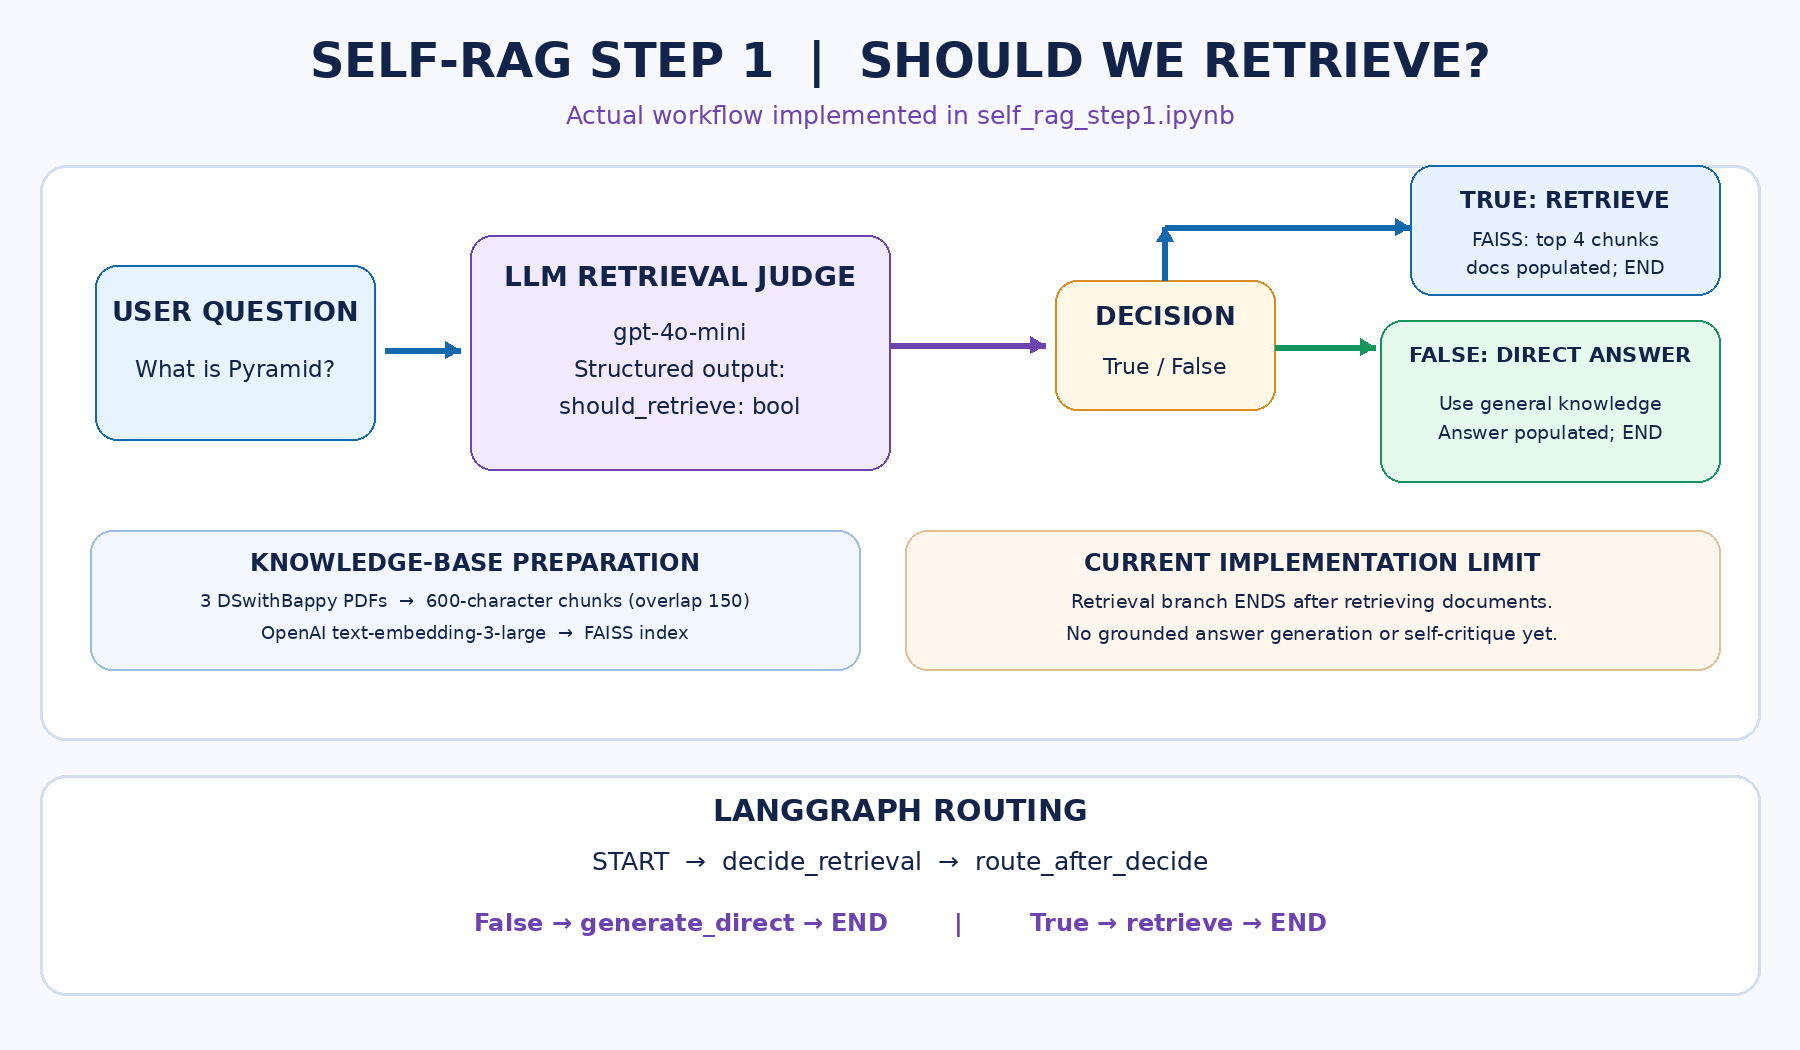

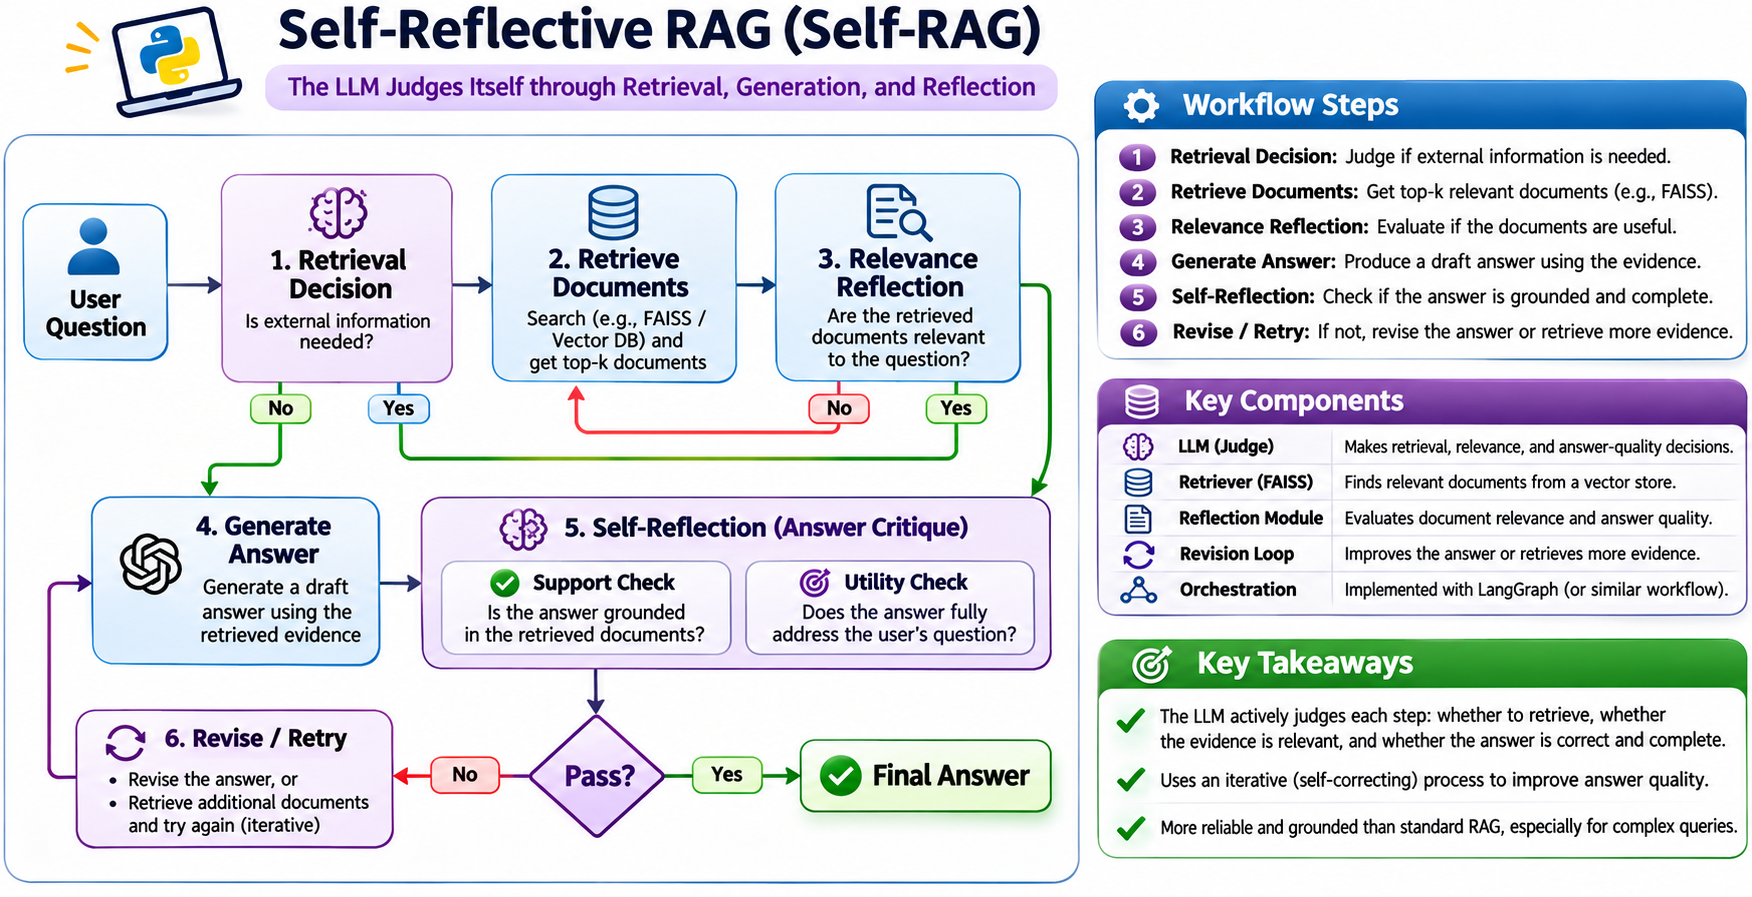


This notebook implements the first stage of **Self-Reflective RAG (Self-RAG)** using LangGraph. An LLM determines whether external knowledge retrieval is necessary before answering a user question.

### 1. Knowledge Base Preparation

- Load three company-related PDF documents using `PyPDFLoader`.
- Split documents into chunks (`chunk_size=600`, `chunk_overlap=150`).
- Generate embeddings using `text-embedding-3-large`.
- Store vectors in FAISS and configure top-4 retrieval.

### 2. Retrieval Decision

The `decide_retrieval()` node uses `gpt-4o-mini` to return structured output:

```python
class RetrieveDecision(BaseModel):
    should_retrieve: bool
```

LangGraph routes the question according to the decision:

- **False:** `generate_direct()` answers using the LLM's general knowledge.
- **True:** `retrieve()` searches FAISS and returns relevant documents.

### 3. LangGraph Workflow

```text
START
  |
  v
decide_retrieval
  |
  +-- False --> generate_direct --> END
  |
  +-- True ---> retrieve --------> END
```

### 4. Key Takeaway

**Adaptive retrieval avoids unnecessary database searches for questions that can be answered directly.**

This notebook implements only the retrieval-decision stage of a Self-RAG-inspired architecture. The retrieval branch currently ends after fetching documents, without generating a document-grounded answer.

Future stages will introduce document relevance evaluation, answer generation, evidence verification, and self-reflection.

In [ ]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_huggingface import HuggingFaceEmbeddings


from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

# Load API credentials and configuration from the project .env file.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

C:\Users\meisa\AppData\Local\Temp\ipykernel_10888\3852774806.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
W1102 19:30:00.828000 10888 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 19:30:00.861000 10888 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [ ]:
# Set False to rebuild the FAISS index from the source PDFs; True loads the saved index.
faiss_saved = True

# Build and save the index when no reusable local index is selected.
if faiss_saved==False:
    # Load the company policy, profile, and pricing PDFs as LangChain Documents.
    docs = (
        PyPDFLoader("./documents/DSwithBappy_Company_Policies.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Company_Profile.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Product_and_Pricing.pdf").load()

    )
    # Split long documents into overlapping passages for retrieval.
    chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
    ).split_documents(docs)
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Embed the chunks and build a FAISS similarity-search index.
    vector_store = FAISS.from_documents(chunks, hf_embeddings)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
    vector_store.save_local("faiss_index")
    
else:
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Restore the saved FAISS index; only load an index you trust.
    vector_store = FAISS.load_local("faiss_index", hf_embeddings, allow_dangerous_deserialization=True)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})


In [5]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [6]:
# --------------------------------------------------
# Graph State
# --------------------------------------------------
class State(TypedDict):
    question: str
    need_retrieval: bool

    docs: List[Document]

    answer: str

In [7]:
# Structured model result for deciding whether retrieval is needed.
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(..., description="True if external documents are needed to answer reliably, else False.")
    

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)


# IMPORTANT: no `.content` for structured output
should_retrieve_llm = llm.with_structured_output(RetrieveDecision)


def decide_retrieval(state: "State"):
    # Decide whether this question needs facts from the local documents.
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    # Store the retrieval decision in the graph state for routing.
    return {"need_retrieval": decision.should_retrieve}

In [8]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)


# Answer general questions without consulting the document collection.
def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {
        "answer": out.content
    }


In [9]:
# Search the FAISS index using the rewritten query when available.
def retrieve(state: State):
    # Save retrieved document chunks in graph state.
    return {"docs": retriever.invoke(state["question"])}

In [10]:
# Select direct answering or retrieval based on the decision in state.
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

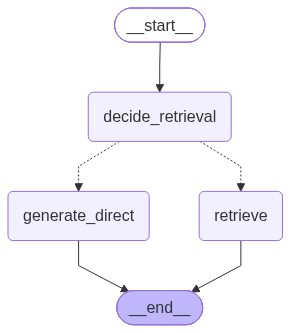

In [11]:
# Create the LangGraph workflow with the shared state schema.
g = StateGraph(State)

# --------------------
# Nodes
# --------------------
g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)

# --------------------
# Edges
# --------------------
g.add_edge(START, "decide_retrieval")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve",
    },
)

g.add_edge("generate_direct", END)
g.add_edge("retrieve", END)  # temporary END for retrieval path

# Compile the nodes and edges into an executable graph.
app = g.compile()
app

In [12]:
# Run the complete Self-RAG workflow for the supplied state.
result = app.invoke(
    {
        "question": "What is Pyramid",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
    }
)

print(result["answer"])

A pyramid is a three-dimensional geometric shape that has a polygonal base and triangular faces that converge at a single point called the apex. The most well-known pyramids are the Egyptian pyramids, which were built as tombs for pharaohs and are characterized by their square bases and four triangular sides. Pyramids can also be found in various cultures around the world, serving different purposes, such as religious or ceremonial structures. In a broader context, the term "pyramid" can also refer to hierarchical structures in various fields, such as business or social organization, where levels of authority or importance are arranged in a pyramid-like shape.


In [13]:
result['need_retrieval']

False

In [14]:
result['docs']

[]